In [5]:
import sys
from pathlib import Path

PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils").is_dir()
)
sys.path.insert(0, str(PROJECT_ROOT))

import importlib
import os
from datetime import UTC, datetime

import cartopy.crs as ccrs
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from dotenv import find_dotenv, load_dotenv

from utils import analysis_utils, isku_utils, plotting_utils

importlib.reload(analysis_utils)
importlib.reload(isku_utils)
importlib.reload(plotting_utils)

<module 'utils.plotting_utils' from '/home/emily_zuetell/projects/poreallas/utils/plotting_utils.py'>

In [6]:
load_dotenv(
    find_dotenv("october_local.env", raise_error_if_not_found=True), override=True
)

EFFECTS_URI = os.environ["POREALLAS_EFFECTS_URI"]
IMPACT_REGION_POLYGONS = os.environ["POREALLAS_REGIONS_POLYGONS_URI"]
SOCIOECONOMICS_URI = os.environ["POREALLAS_SOCIOECONOMICS_URI"]

In [7]:
# Baseline period for Impact
effect = xr.open_datatree(EFFECTS_URI, consolidated=False)
BASELINE_PERIOD = analysis_utils.get_baseline_period(effect, years=30)
# Define Forecast Months
FC_MONTHS = [10, 11, 12, 1, 2, 3]

config = analysis_utils.ImpactConfig(
    version=f"v{datetime.now(tz=UTC):%y%m%d}",
    baseline_period=BASELINE_PERIOD,
    polygons_path=os.environ["POREALLAS_REGIONS_POLYGONS_URI"],
    socioeconomics_path=os.environ["POREALLAS_SOCIOECONOMICS_URI"],
    rate=True,
    age_weight=True,
    months=FC_MONTHS,
    hotonly="hotonly",
    dims=["number", "sample"],
)

In [8]:
def _flat(da):
    # Flatten and check xarray
    v = np.asarray(da).ravel()
    return v[np.isfinite(v)]


def load_panel_a(path):
    ds = xr.open_zarr(path, consolidated=True).load()
    return ds["ens_mean"], ds["agreement"], ds.attrs


def load_panel_b(path, pad=3):
    ds = xr.open_zarr(path, consolidated=True).load()
    fc, era5 = ds["fc_tas"], ds["era5_tas"]
    vals = np.concatenate([_flat(fc), _flat(era5)])
    clim = {
        "forecast": fc,
        "era5": era5,
        "n_members": fc.sizes["number"],
        "n_years": np.unique(era5["era5_time"].dt.year).size,
        "xlim": (vals.min() - pad, vals.max() + pad),
    }
    beta = {
        "samples": ds["beta"].values,
        "tas_bin": ds["tas_bin"].values,
        "mmt": ds["mmt"].item(),
    }
    return clim, beta, ds.attrs


def load_panel_c(path, polygons):
    ds = xr.open_zarr(path, consolidated=True).load()
    gdf = analysis_utils.xarray_to_gpd(ds["beta_slope_at_forecast"], polygons)
    return gdf.to_crs(ccrs.Robinson().proj4_init), ds.attrs

In [9]:
FIG1C_PATH = "../data/figures/v261118_fig1c.zarr"
gdf_rob, attrs_c = load_panel_c(FIG1C_PATH, config.polygons)

In [10]:
config_rate = analysis_utils.ImpactConfig(
    version=f"v{datetime.now(tz=UTC):%y%m%d}",
    baseline_period=BASELINE_PERIOD,
    polygons_path=os.environ["POREALLAS_REGIONS_POLYGONS_URI"],
    socioeconomics_path=os.environ["POREALLAS_SOCIOECONOMICS_URI"],
    rate=True,
    age_weight=True,
    months=FC_MONTHS,
    hotonly="hotonly",
    dims=["number", "sample"],
)
# Compute impact: forecast - baseline
impact_rate = analysis_utils.compute_impact(
    effect.chunk({dim: -1 for dim in config.dims}),
    config_rate,
    ensemble=True,
).sel(month=config.months)

impact_rate_ir = impact_rate.sum(dim = 'month').mean(dim = ['number', 'sample'])
impact_rate_df = impact_rate_ir.to_dataframe()

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


In [11]:
forecast = xr.open_zarr(
    "../data/v2610/v20261006_parsed_forecast.zarr"
)
forecast_month = (
    forecast.groupby("time.month").mean().sel(month=config.months)
)

ens_mean_ir = isku_utils.grid_to_ir(forecast_month.mean(dim = ['month', 'number'])-273.15)

ens_mean_df = ens_mean_ir.to_dataframe()

merged = ens_mean_df.merge(gdf_rob, on = 'region')

gdp_df = config.socioeconomics['gdppc'].to_dataframe(name = 'gdppc')
merged = merged.merge(gdp_df, on = 'region')

/home/emily_zuetell/projects/poreallas/utils/isku_utils.py:28: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  _region_weights = xr.load_dataset(uri)[
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/zarr/core/group.py:3289: ZarrUserWarning: Object at zarr.json:Zone.Identifier is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


(0.0, 32.0)

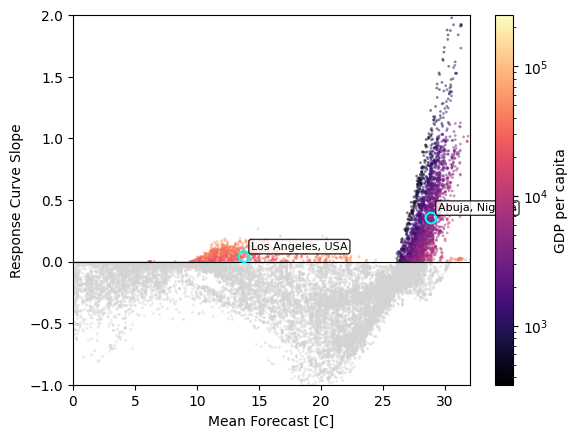

In [13]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import seaborn as sns

d = merged[merged["gdppc"] > 0]
norm = LogNorm(vmin=d["gdppc"].min(), vmax=d["gdppc"].max())
neg = d["beta_slope_at_forecast"] < 0

ax = sns.scatterplot(data=d[neg], x="tas", y="beta_slope_at_forecast",
                     color="lightgray", s=4, alpha=0.5, linewidth=0)
sns.scatterplot(data=d[~neg], x="tas", y="beta_slope_at_forecast",
                hue="gdppc", hue_norm=norm, palette="magma",
                s=4, alpha=0.5, linewidth=0, legend=False, ax=ax)

sm = plt.cm.ScalarMappable(cmap="magma", norm=norm)
ax.figure.colorbar(sm, ax=ax, label="GDP per capita")
ax.axhline(0, color="k", lw=0.8)

highlight_ids = ["USA.5.202", "NGA.6.117"]
labels = {"USA.5.202": "Los Angeles, USA", "NGA.6.117": "Abuja, Nigeria"}
hl = d[d["region"].isin(highlight_ids)]

ax.scatter(hl["tas"], hl["beta_slope_at_forecast"],
           s=60, facecolors="none", edgecolors="cyan", linewidths=1.5, zorder=5)

for _, row in hl.iterrows():
    ax.annotate(labels[row["region"]], (row["tas"], row["beta_slope_at_forecast"]),
                xytext=(5, 5), textcoords="offset points", fontsize=8,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8), zorder=6)
    
plt.xlabel('Mean Forecast [C]')
plt.ylabel('Response Curve Slope')
plt.ylim(-1, 2)
plt.xlim(0, 32)